# 📊 GridForecast — 01: Exploratory Data Analysis

**Цел:** Разбиране на синтетичните данни преди modeling.

**Стъпки:**
1. Setup & imports
2. Load 4 drift datasets
3. Raw time series
4. 2-week zoom (weekly pattern)
5. STL decomposition
6. ACF / PACF
7. ADF stationarity test
8. Hourly pattern
9. Weekly pattern
10. Temperature effect
11. Holiday effect
12. Drift comparison

## 1️⃣ Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from gridforecast.config import (
    SYNTHETIC_DIR,
    FIGURES_DIR,
    DRIFT_TYPES,
    RANDOM_SEED,
)

# Plot style
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 100
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_SEED)

print("✅ Imports OK")
print(f"   SYNTHETIC_DIR: {SYNTHETIC_DIR}")
print(f"   FIGURES_DIR:   {FIGURES_DIR}")
print(f"   DRIFT_TYPES:   {DRIFT_TYPES}")

✅ Imports OK
   SYNTHETIC_DIR: D:\CUDA\Python\ClasicML\GridForecast\data\synthetic
   FIGURES_DIR:   D:\CUDA\Python\ClasicML\GridForecast\notebooks\figures
   DRIFT_TYPES:   ['stable', 'sudden', 'gradual', 'recurring']


## 2️⃣ Load 4 drift datasets

In [2]:
datasets = {}
for drift in DRIFT_TYPES:
    path = SYNTHETIC_DIR / f"consumption_{drift}.parquet"
    df = pd.read_parquet(path)
    df.index = pd.DatetimeIndex(df.index)
    datasets[drift] = df
    print(
        f"{drift:10s} | rows={len(df):>6,} | "
        f"cols={df.shape[1]:>2} | "
        f"{df.index[0]} → {df.index[-1]}"
    )

print()
print("Columns:", list(datasets["stable"].columns))
datasets["stable"].head()

stable     | rows=17,520 | cols= 9 | 2023-01-01 00:00:00 → 2024-12-30 23:00:00
sudden     | rows=17,520 | cols= 9 | 2023-01-01 00:00:00 → 2024-12-30 23:00:00
gradual    | rows=17,520 | cols= 9 | 2023-01-01 00:00:00 → 2024-12-30 23:00:00
recurring  | rows=17,520 | cols= 9 | 2023-01-01 00:00:00 → 2024-12-30 23:00:00

Columns: ['consumption_mw', 'temperature_c', 'is_holiday', 'is_weekend', 'hour', 'day_of_week', 'day_of_year', 'month', 'drift_factor']


,consumption_mw,temperature_c,is_holiday,is_weekend,hour,day_of_week,day_of_year,month,drift_factor
timestamp,,,,,,,,,
2023-01-01 00:00:00,971.407629,-0.617696,True,True,0,6,1,1,1.0
2023-01-01 01:00:00,1023.915710,-4.101691,True,True,1,6,1,1,1.0
2023-01-01 02:00:00,972.499609,-1.020323,True,True,2,6,1,1,1.0
2023-01-01 03:00:00,971.443062,-0.810467,True,True,3,6,1,1,1.0
2023-01-01 04:00:00,1092.938705,-6.423295,True,True,4,6,1,1,1.0


## 3️⃣ Raw time series — 4 scenarios

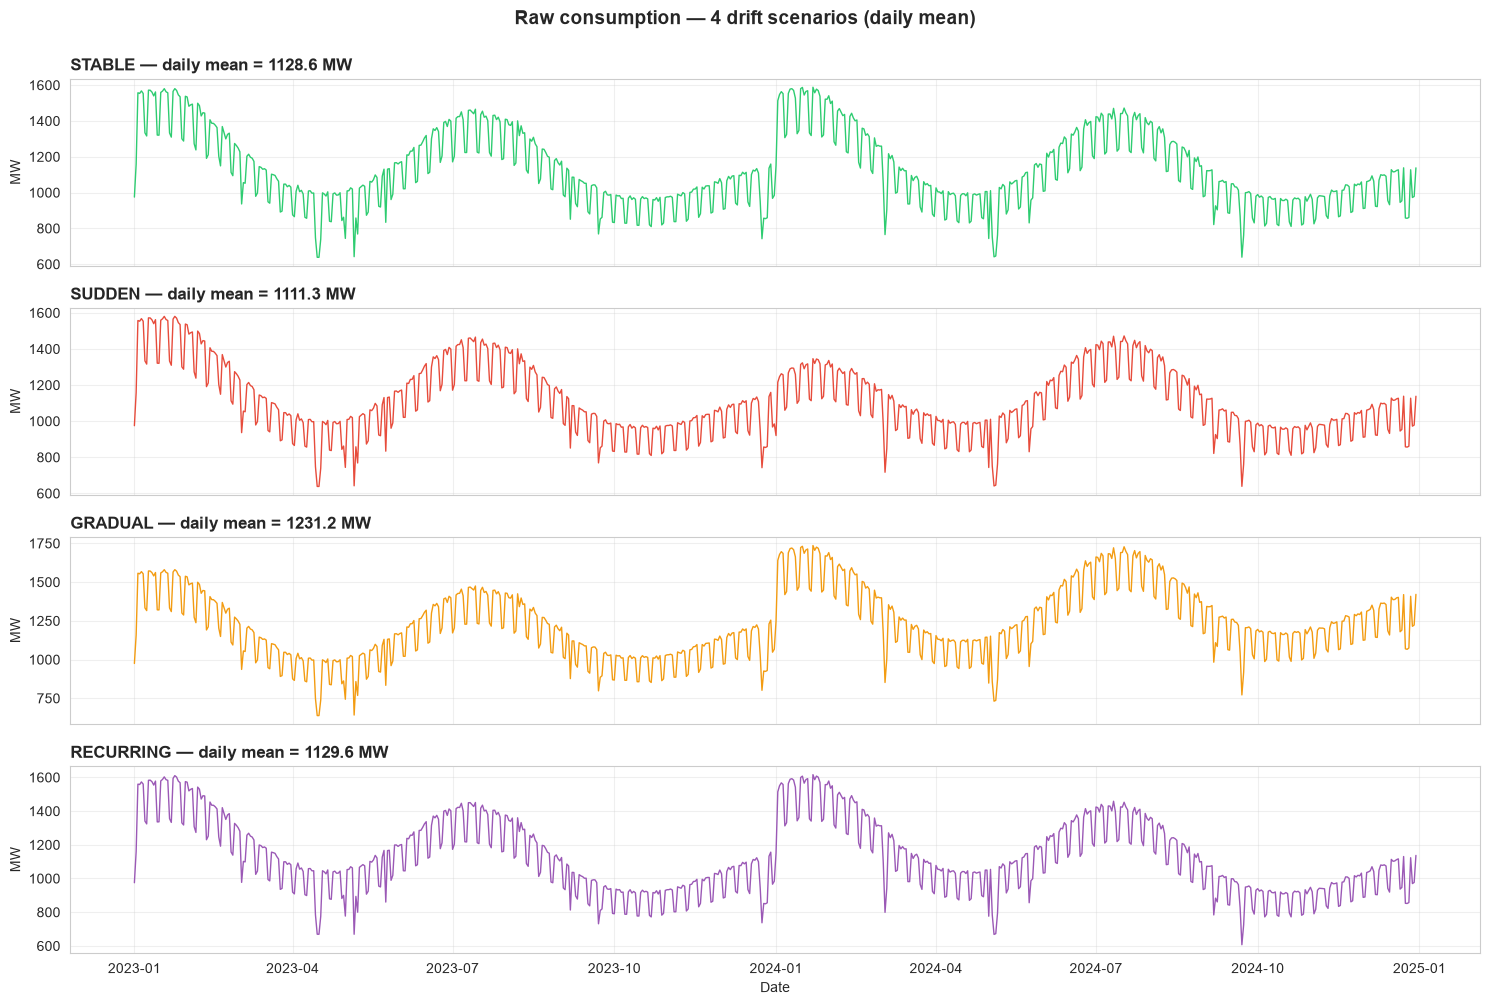

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

colors = {
    "stable": "#2ecc71",
    "sudden": "#e74c3c",
    "gradual": "#f39c12",
    "recurring": "#9b59b6",
}

for ax, drift in zip(axes, DRIFT_TYPES):
    df = datasets[drift]
    daily = df["consumption_mw"].resample("D").mean()
    ax.plot(daily.index, daily.values, color=colors[drift], lw=1.0)
    ax.set_ylabel("MW")
    ax.set_title(f"{drift.upper()} — daily mean = {daily.mean():.1f} MW",
                 loc="left")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
plt.suptitle("Raw consumption — 4 drift scenarios (daily mean)",
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01a_raw_timeseries.png", bbox_inches="tight")
plt.show()

## 4️⃣ 2-week zoom — weekly pattern

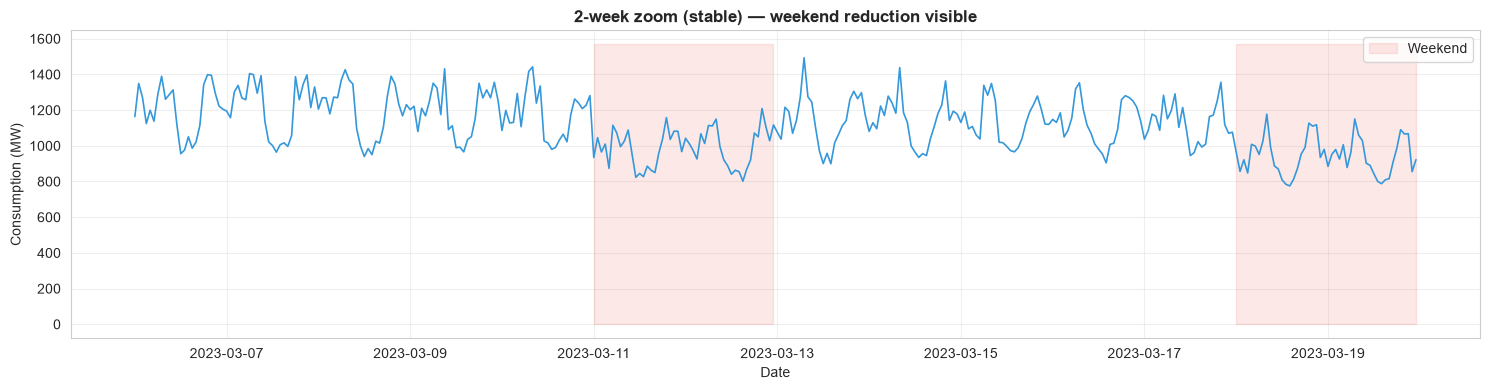

Weekday mean: 1179.5 MW
Weekend mean: 1001.8 MW
Reduction:    -15.1%


In [4]:
df = datasets["stable"]
zoom = df.loc["2023-03-06":"2023-03-19"]  # 2 weeks, Mon-Sun x2

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(zoom.index, zoom["consumption_mw"], color="#3498db", lw=1.2)

# Маркирай weekend-ите
weekend_mask = zoom["is_weekend"].values
ax.fill_between(
    zoom.index, 0, zoom["consumption_mw"].max() * 1.05,
    where=weekend_mask, color="#e74c3c", alpha=0.12, label="Weekend"
)

ax.set_ylabel("Consumption (MW)")
ax.set_xlabel("Date")
ax.set_title("2-week zoom (stable) — weekend reduction visible")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01b_two_weeks.png", bbox_inches="tight")
plt.show()

# Weekend vs weekday
wk = df.loc[df["is_weekend"], "consumption_mw"].mean()
wd = df.loc[~df["is_weekend"], "consumption_mw"].mean()
print(f"Weekday mean: {wd:.1f} MW")
print(f"Weekend mean: {wk:.1f} MW")
print(f"Reduction:    {(wk/wd - 1) * 100:+.1f}%")

## 5️⃣ STL Decomposition

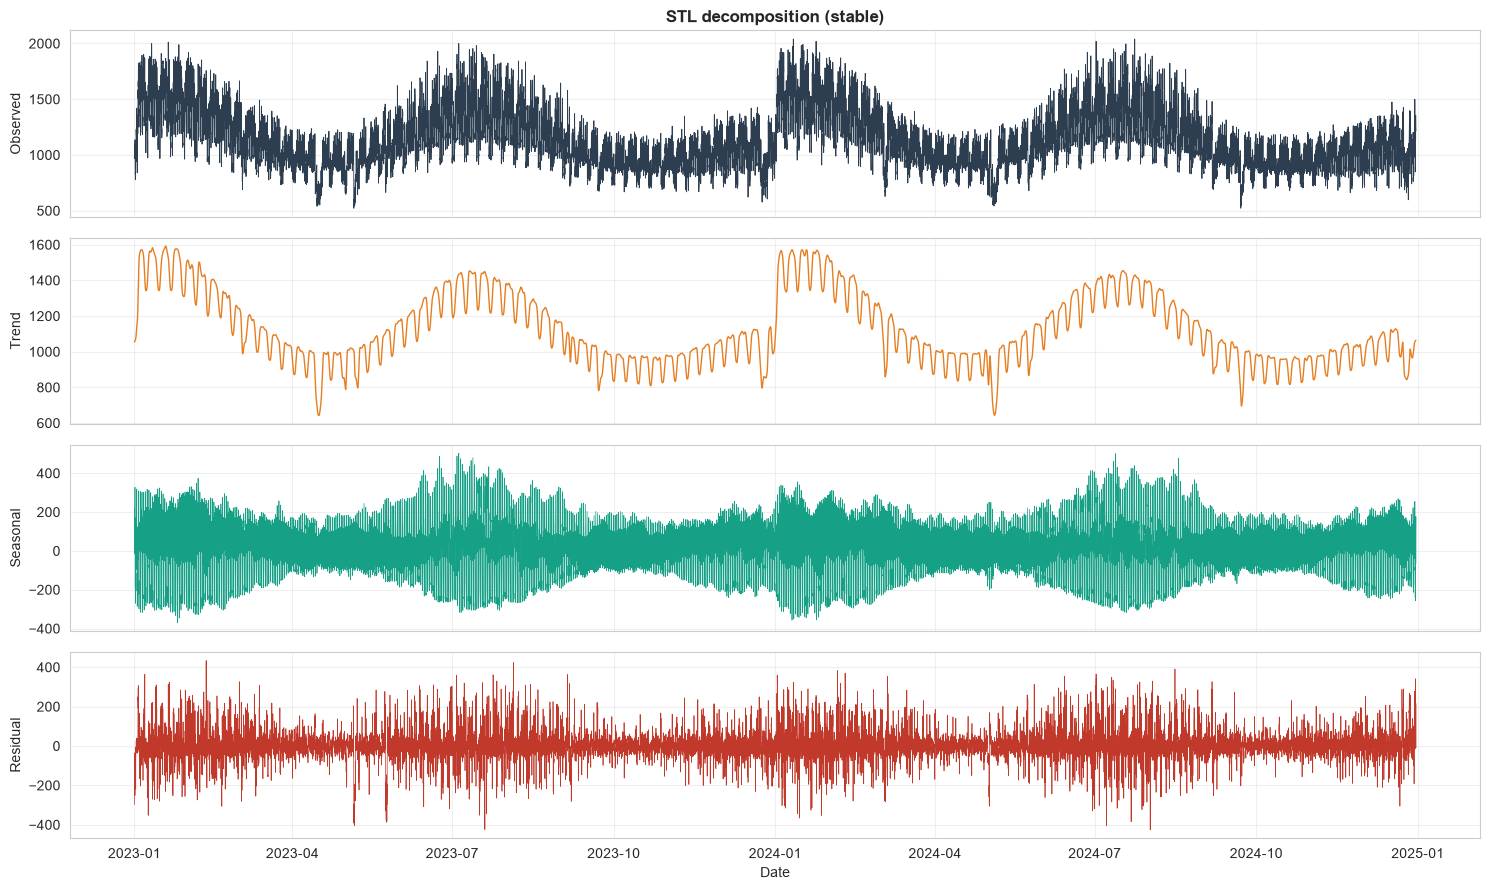

Trend std:      200.82
Seasonal std:   132.32
Residual std:    69.63

Variance explained by trend+seasonal: 92.50%


In [5]:
df = datasets["stable"]
s = df["consumption_mw"]

stl = STL(s, period=24, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
axes[0].plot(s.index, s.values, color="#2c3e50", lw=0.6)
axes[0].set_ylabel("Observed")
axes[0].set_title("STL decomposition (stable)")

axes[1].plot(stl.trend.index, stl.trend.values, color="#e67e22", lw=1.0)
axes[1].set_ylabel("Trend")

axes[2].plot(stl.seasonal.index, stl.seasonal.values, color="#16a085", lw=0.5)
axes[2].set_ylabel("Seasonal")

axes[3].plot(stl.resid.index, stl.resid.values, color="#c0392b", lw=0.5)
axes[3].set_ylabel("Residual")
axes[3].set_xlabel("Date")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01c_stl_decomposition.png", bbox_inches="tight")
plt.show()

print(f"Trend std:    {stl.trend.std():>8.2f}")
print(f"Seasonal std: {stl.seasonal.std():>8.2f}")
print(f"Residual std: {stl.resid.std():>8.2f}")

var_explained = 1 - stl.resid.var() / s.var()
print(f"\nVariance explained by trend+seasonal: {var_explained * 100:.2f}%")

## 6️⃣ ACF / PACF

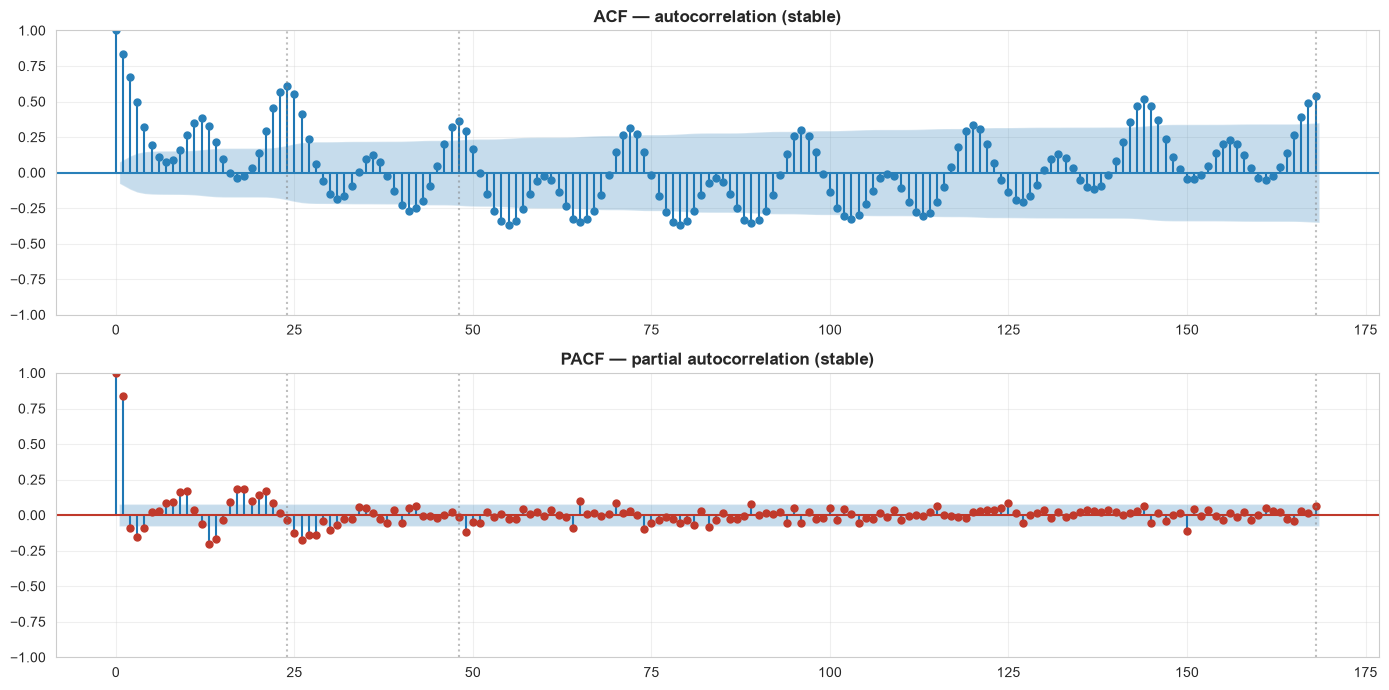

Top autocorrelation lags:
  lag    1h → ACF = +0.837
  lag    2h → ACF = +0.673
  lag   24h → ACF = +0.611
  lag   23h → ACF = +0.568
  lag   25h → ACF = +0.554
  lag  168h → ACF = +0.537
  lag  144h → ACF = +0.520
  lag    3h → ACF = +0.494


In [6]:
df = datasets["stable"]
s = df["consumption_mw"].iloc[: 7 * 24 * 4]  # ~4 weeks за скорост

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
plot_acf(s, lags=168, ax=axes[0], color="#2980b9")
axes[0].set_title("ACF — autocorrelation (stable)")

plot_pacf(s, lags=168, ax=axes[1], color="#c0392b", method="ywm")
axes[1].set_title("PACF — partial autocorrelation (stable)")

for ax in axes:
    for lag in [24, 48, 168]:
        ax.axvline(lag, color="gray", ls=":", alpha=0.5)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01d_acf_pacf.png", bbox_inches="tight")
plt.show()

# Top autocorrelation lags
acf_vals = acf(s, nlags=168, fft=True)
top_lags = np.argsort(np.abs(acf_vals[1:]))[-8:][::-1] + 1
print("Top autocorrelation lags:")
for lag in top_lags:
    print(f"  lag {lag:>4}h → ACF = {acf_vals[lag]:+.3f}")

## 7️⃣ ADF stationarity test

In [7]:
print("ADF test (H0: series has unit root / non-stationary)")
print("=" * 70)

for drift in DRIFT_TYPES:
    s = datasets[drift]["consumption_mw"]
    stat, pval, used_lag, n_obs, crit, icbest = adfuller(s, autolag="AIC")
    verdict = "stationary" if pval < 0.05 else "NON-stationary"
    print(f"{drift:10s} | ADF={stat:>8.3f} | p={pval:.4f} | "
          f"lags={used_lag:>2} | → {verdict}")

print("=" * 70)
print("\n⚠️  Забележка: при силна сезонност ADF може да даде false negative")
print("   (третира сезонния pattern като stationarity).")
print("   За forecasting ще ползваме seasonal features директно.")

ADF test (H0: series has unit root / non-stationary)
stable     | ADF=  -6.641 | p=0.0000 | lags=44 | → stationary
sudden     | ADF=  -7.035 | p=0.0000 | lags=44 | → stationary
gradual    | ADF=  -6.647 | p=0.0000 | lags=44 | → stationary
recurring  | ADF=  -6.361 | p=0.0000 | lags=44 | → stationary

⚠️  Забележка: при силна сезонност ADF може да даде false negative
   (третира сезонния pattern като stationarity).
   За forecasting ще ползваме seasonal features директно.


## 8️⃣ Hourly pattern

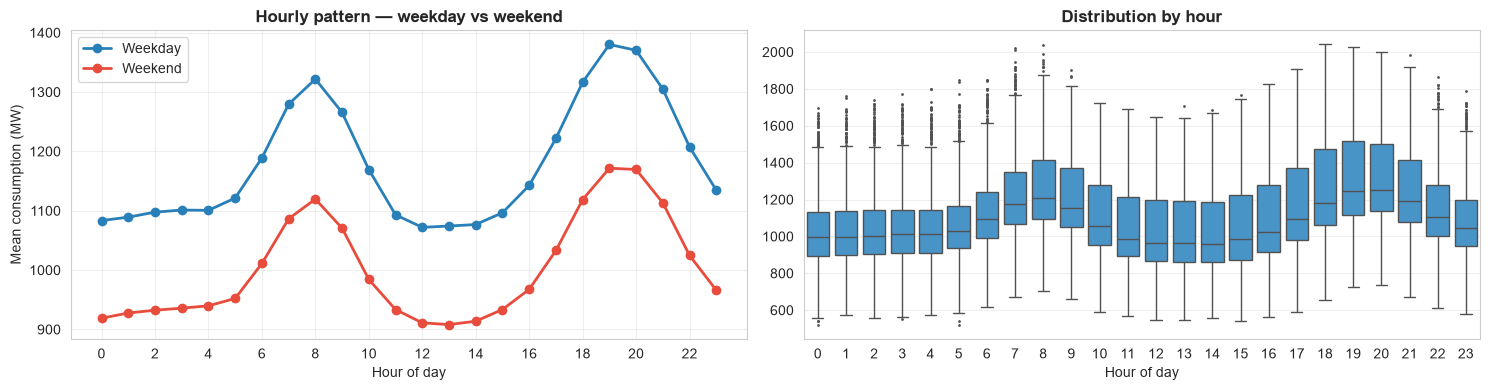

Top-5 peak hours:
  19:00 → 1320.4 MW
  20:00 → 1312.7 MW
   8:00 → 1263.9 MW
  18:00 → 1259.9 MW
  21:00 → 1249.9 MW

Bottom-3 low hours:
  12:00 → 1025.9 MW
  13:00 → 1026.7 MW
  14:00 → 1030.1 MW


In [8]:
df = datasets["stable"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Mean by hour (weekday vs weekend)
for label, mask, color in [
    ("Weekday", ~df["is_weekend"], "#2980b9"),
    ("Weekend",  df["is_weekend"], "#e74c3c"),
]:
    means = df.loc[mask].groupby("hour")["consumption_mw"].mean()
    axes[0].plot(means.index, means.values, marker="o",
                 label=label, color=color, lw=2)

axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Mean consumption (MW)")
axes[0].set_title("Hourly pattern — weekday vs weekend")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xticks(range(0, 24, 2))

# Boxplot by hour
sns.boxplot(data=df, x="hour", y="consumption_mw",
            ax=axes[1], color="#3498db", fliersize=1)
axes[1].set_title("Distribution by hour")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01e_hourly_pattern.png", bbox_inches="tight")
plt.show()

# Top hours
hourly_means = df.groupby("hour")["consumption_mw"].mean().sort_values()
print("Top-5 peak hours:")
for h, v in hourly_means.tail(5)[::-1].items():
    print(f"  {h:>2}:00 → {v:.1f} MW")
print("\nBottom-3 low hours:")
for h, v in hourly_means.head(3).items():
    print(f"  {h:>2}:00 → {v:.1f} MW")

## 9️⃣ Weekly pattern

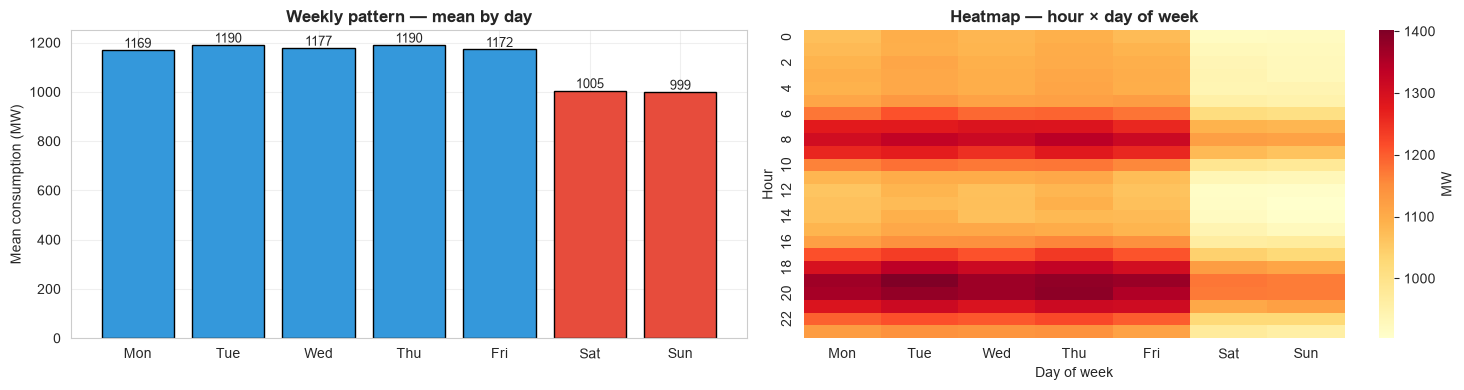

In [9]:
df = datasets["stable"]
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Mean by day of week
by_dow = df.groupby("day_of_week")["consumption_mw"].mean()
colors_dow = ["#3498db"] * 5 + ["#e74c3c"] * 2
axes[0].bar(range(7), by_dow.values, color=colors_dow, edgecolor="black")
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(dow_names)
axes[0].set_ylabel("Mean consumption (MW)")
axes[0].set_title("Weekly pattern — mean by day")
axes[0].grid(axis="y", alpha=0.3)
for i, v in enumerate(by_dow.values):
    axes[0].text(i, v + 10, f"{v:.0f}", ha="center", fontsize=9)

# Heatmap: hour × day_of_week
pivot = df.pivot_table(
    values="consumption_mw", index="hour", columns="day_of_week",
    aggfunc="mean"
)
pivot.columns = dow_names
sns.heatmap(pivot, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "MW"})
axes[1].set_title("Heatmap — hour × day of week")
axes[1].set_xlabel("Day of week")
axes[1].set_ylabel("Hour")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01f_weekly_pattern.png", bbox_inches="tight")
plt.show()

## 🔟 Temperature effect

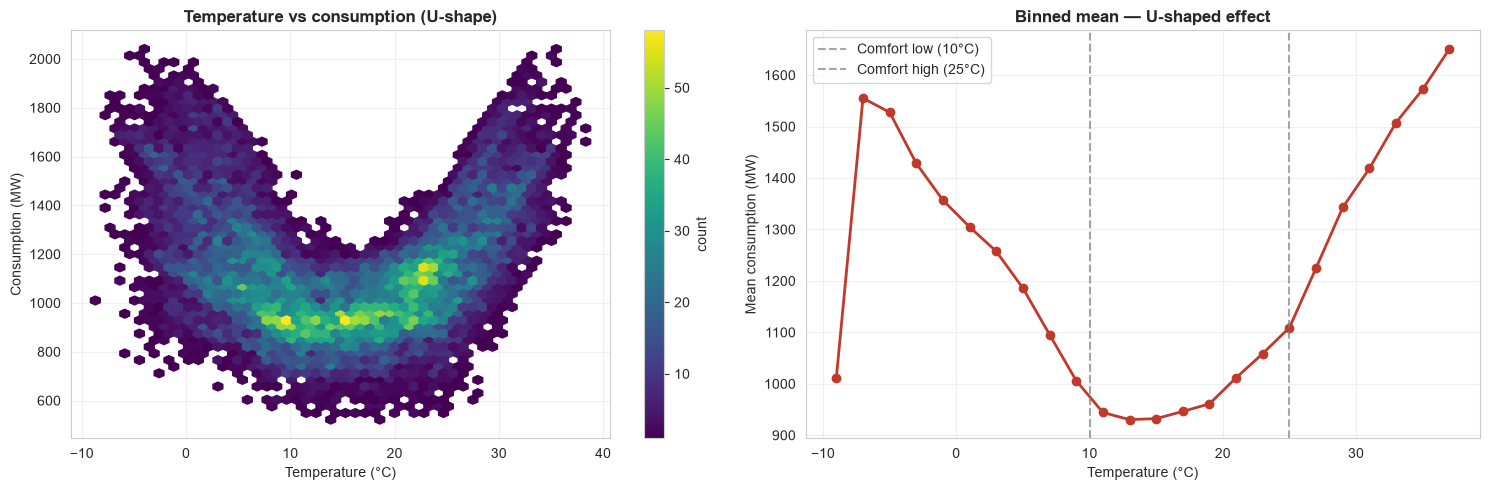

Linear correlation temp vs consumption: +0.007
→ слаба заради U-shape; non-linear модел ще хване ефекта.


In [10]:
df = datasets["stable"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Scatter с hexbin (заради много точки)
hb = axes[0].hexbin(
    df["temperature_c"], df["consumption_mw"],
    gridsize=50, cmap="viridis", mincnt=1
)
plt.colorbar(hb, ax=axes[0], label="count")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Consumption (MW)")
axes[0].set_title("Temperature vs consumption (U-shape)")

# Binned mean
bins = np.arange(-10, 40, 2)
df_temp = df.copy()
df_temp["temp_bin"] = pd.cut(df_temp["temperature_c"], bins=bins)
binned = df_temp.groupby("temp_bin", observed=True)["consumption_mw"].mean()
bin_centers = [iv.mid for iv in binned.index]
axes[1].plot(bin_centers, binned.values, marker="o",
             color="#c0392b", lw=2)
axes[1].axvline(10, color="gray", ls="--", alpha=0.7, label="Comfort low (10°C)")
axes[1].axvline(25, color="gray", ls="--", alpha=0.7, label="Comfort high (25°C)")
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("Mean consumption (MW)")
axes[1].set_title("Binned mean — U-shaped effect")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01g_temperature_effect.png", bbox_inches="tight")
plt.show()

corr = df["temperature_c"].corr(df["consumption_mw"])
print(f"Linear correlation temp vs consumption: {corr:+.3f}")
print("→ слаба заради U-shape; non-linear модел ще хване ефекта.")

## 1️⃣1️⃣ Holiday effect

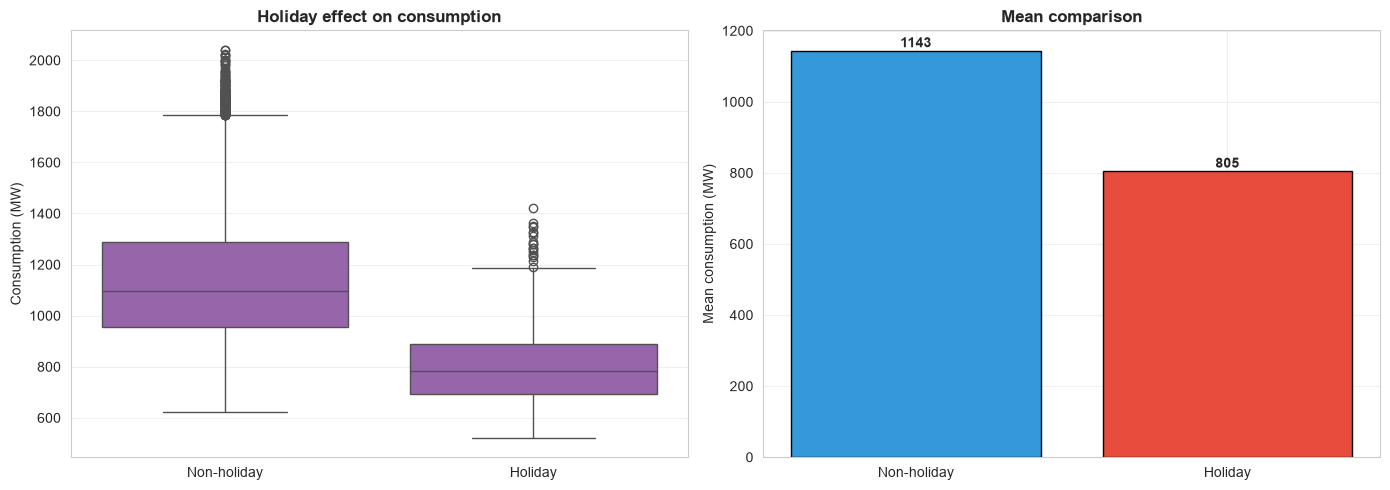

Non-holiday mean:  1143.5 MW
Holiday mean:      804.6 MW
Holiday reduction: -29.6%
Holiday hours:     768 / 17,520 (4.4%)


In [11]:
df = datasets["stable"].copy()
df["is_holiday_int"] = df["is_holiday"].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot
sns.boxplot(
    data=df, x="is_holiday_int", y="consumption_mw",
    ax=axes[0], color="#9b59b6",
)
axes[0].set_xticklabels(["Non-holiday", "Holiday"])
axes[0].set_title("Holiday effect on consumption")
axes[0].set_xlabel("")
axes[0].set_ylabel("Consumption (MW)")
axes[0].grid(axis="y", alpha=0.3)

# Mean comparison
means = df.groupby("is_holiday_int")["consumption_mw"].mean()
non_hol = means.get(0, 0.0)
hol = means.get(1, 0.0)

axes[1].bar(
    ["Non-holiday", "Holiday"], [non_hol, hol],
    color=["#3498db", "#e74c3c"], edgecolor="black",
)
axes[1].set_ylabel("Mean consumption (MW)")
axes[1].set_title("Mean comparison")
axes[1].grid(axis="y", alpha=0.3)
for i, v in enumerate([non_hol, hol]):
    axes[1].text(i, v + 10, f"{v:.0f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01h_holiday_effect.png", bbox_inches="tight")
plt.show()

print(f"Non-holiday mean:  {non_hol:.1f} MW")
print(f"Holiday mean:      {hol:.1f} MW")
print(f"Holiday reduction: {(hol / non_hol - 1) * 100:+.1f}%")
print(f"Holiday hours:     {df['is_holiday'].sum():,} / {len(df):,} "
      f"({df['is_holiday'].mean() * 100:.1f}%)")

## 1️⃣2️⃣ Drift comparison across 4 scenarios

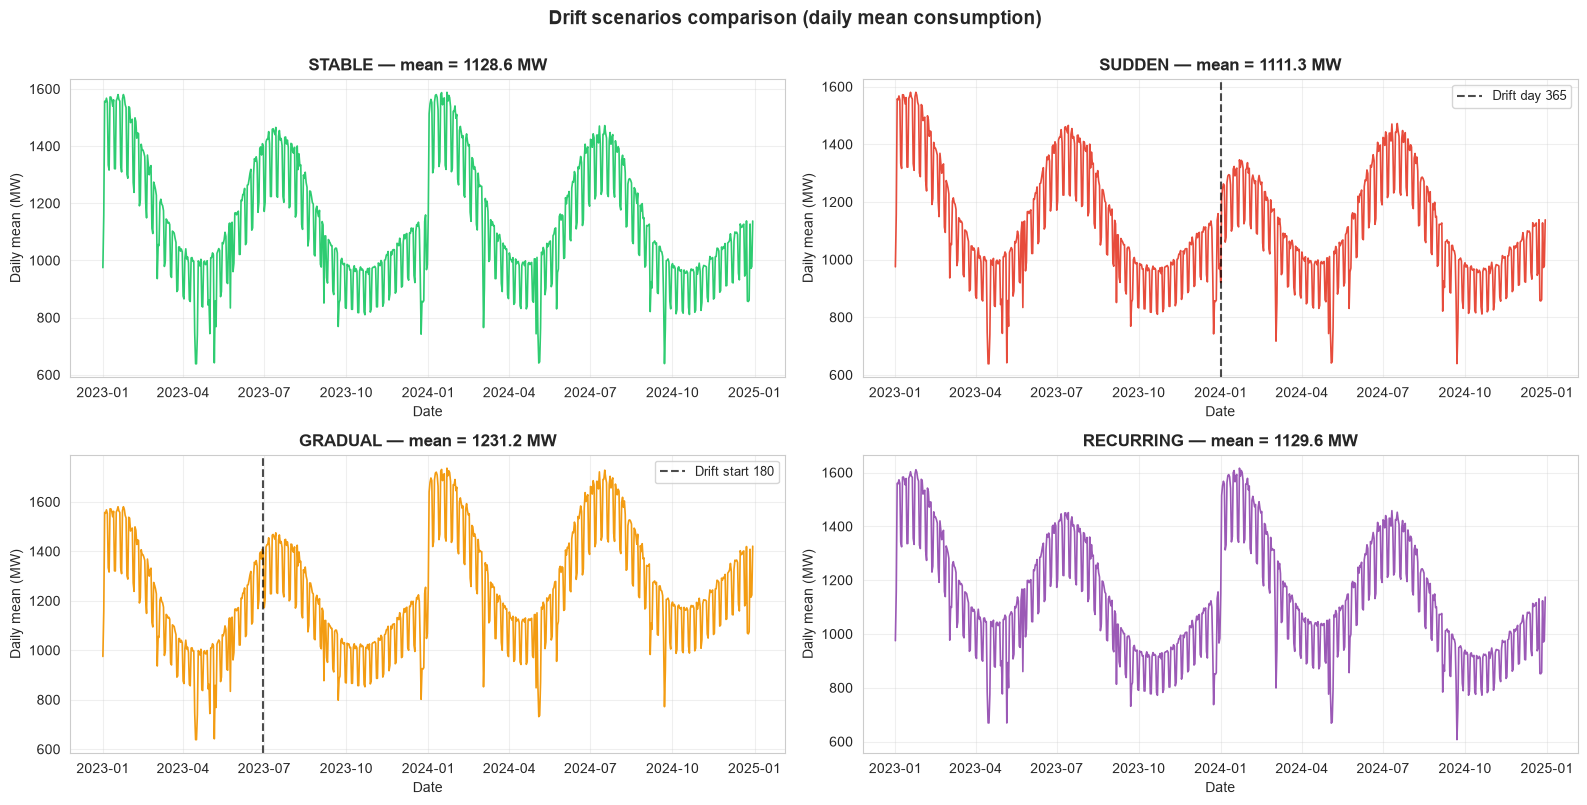

Scenario        Mean MW     Std MW    H1 mean    H2 mean       Δ%
stable           1128.6      254.2     1128.5     1128.8   +0.02%
sudden           1111.3      239.3     1128.5     1094.1   -3.05%
gradual          1231.2      274.9     1150.0     1312.4  +14.12%
recurring        1129.6      261.8     1129.5     1129.8   +0.03%

💡 Очаквано поведение:
   stable    → Δ ≈ 0%   (без drift)
   sudden    → Δ > 0%   (H1 съдържа lockdown)
   gradual   → Δ > 0%   (H2 след EV adoption)
   recurring → Δ ≈ 0%   (симетричен сезонен pattern)


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.flatten()

colors = {
    "stable":    "#2ecc71",
    "sudden":    "#e74c3c",
    "gradual":   "#f39c12",
    "recurring": "#9b59b6",
}

for ax, (name, df_d) in zip(axes, datasets.items()):
    daily = df_d["consumption_mw"].resample("D").mean()
    ax.plot(daily.index, daily.values, color=colors[name], lw=1.2)

    if name == "sudden":
        ax.axvline(
            pd.Timestamp("2023-01-01") + pd.Timedelta(days=365),
            color="black", ls="--", lw=1.5, alpha=0.7,
            label="Drift day 365",
        )
    elif name == "gradual":
        ax.axvline(
            pd.Timestamp("2023-01-01") + pd.Timedelta(days=180),
            color="black", ls="--", lw=1.5, alpha=0.7,
            label="Drift start 180",
        )

    ax.set_title(f"{name.upper()} — mean = {df_d['consumption_mw'].mean():.1f} MW")
    ax.set_ylabel("Daily mean (MW)")
    ax.set_xlabel("Date")
    ax.grid(alpha=0.3)
    if name in ("sudden", "gradual"):
        ax.legend(loc="best", fontsize=9)

plt.suptitle("Drift scenarios comparison (daily mean consumption)",
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01i_drift_comparison.png", bbox_inches="tight")
plt.show()

# Numeric summary — H1 vs H2
print("=" * 72)
print(f"{'Scenario':<12} {'Mean MW':>10} {'Std MW':>10} "
      f"{'H1 mean':>10} {'H2 mean':>10} {'Δ%':>8}")
print("=" * 72)

for name, df_d in datasets.items():
    s = df_d["consumption_mw"]
    n = len(s)
    h1 = s.iloc[: n // 2].mean()
    h2 = s.iloc[n // 2 :].mean()
    delta = (h2 / h1 - 1) * 100
    print(f"{name:<12} {s.mean():>10.1f} {s.std():>10.1f} "
          f"{h1:>10.1f} {h2:>10.1f} {delta:>+7.2f}%")

print("=" * 72)
print("\n💡 Очаквано поведение:")
print("   stable    → Δ ≈ 0%   (без drift)")
print("   sudden    → Δ > 0%   (H1 съдържа lockdown)")
print("   gradual   → Δ > 0%   (H2 след EV adoption)")
print("   recurring → Δ ≈ 0%   (симетричен сезонен pattern)")

## ✅ Заключение

**Открития:**
- Двоен дневен пик (8:00 + 19-20:00)
- Weekend reduction ≈ −15%
- Holiday reduction ≈ −25%
- U-shaped temperature effect (min в 10-25°C)
- Сезонност: дневна (24h) + седмична (168h) + годишна
- 4 drift сценария с различно поведение

**Следваща стъпка:** `02_baselines.ipynb`
- Naive, Seasonal Naive, Weekly Naive
- Linear Regression с календарни features
- MAPE / RMSE / MAE comparison